# 8-1. 리샘플링 커버리지 vs 자체 커버리지 (조건: 모든 파라미터 동일)

외부 피드백: 캘리브레이션(리샘플링) 없이 모델 자체 신뢰구간으로 채점한다. 공정한 비교를 위해 **점예측·파라미터가 같은 모델 위에서 구간생성법(리샘플링 vs 자체 σ)만 다르게** 한다.

매 origin에서 `auto_arima`를 기본상태로 한 번 fit하고, (A) 과거 잔차 리샘플링 구간과 (B) 모델 자체 σ 구간을 만들어 커버리지·CRPS로 비교한다.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import pmdarima as pm
import properscoring as ps
from scipy import stats

H = 4
MIN_TRAIN = 20
INITIAL_CALIB = 15
TARGET_VAR = "X3_l1"
ALPHA = 0.10
Z = stats.norm.ppf(1 - ALPHA / 2)
N_RESAMPLE = 500

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
quarters = raw[["quarter", TARGET_VAR]].dropna()["quarter"].reset_index(drop=True).values
vals = raw[["quarter", TARGET_VAR]].dropna()[TARGET_VAR].values.astype(float)
n = len(vals)
var_std = vals.std()
origins = list(range(MIN_TRAIN, n - H + 1))
scored_origins = origins[INITIAL_CALIB:]
print(f"전체 origin {len(origins)}개, 채점 origin(INITIAL_CALIB={INITIAL_CALIB} 이후만) {len(scored_origins)}개")


전체 origin 37개, 채점 origin(INITIAL_CALIB=15 이후만) 22개


In [2]:
preview_rows = []
for label, o in [("첫 채점 origin", scored_origins[0]),
                  ("중간 채점 origin", scored_origins[len(scored_origins) // 2]),
                  ("마지막 채점 origin", scored_origins[-1])]:
    preview_rows.append({
        "구분": label, "origin": o,
        "훈련기간": f"{quarters[0]} ~ {quarters[o - 1]}", "훈련분기수": o,
        "채점기간(h=1~4)": f"{quarters[o]} ~ {quarters[o + H - 1]}",
    })
display(pd.DataFrame(preview_rows))


,구분,origin,훈련기간,훈련분기수,채점기간(h=1~4)
0,첫 채점 origin,35,2011Q1 ~ 2019Q3,35,2019Q4 ~ 2020Q3
1,중간 채점 origin,46,2011Q1 ~ 2022Q2,46,2022Q3 ~ 2023Q2
2,마지막 채점 origin,56,2011Q1 ~ 2024Q4,56,2025Q1 ~ 2025Q4


## 1. 하나의 모델에서 두 구간 계산

훈련구간은 20개 분기에서 시작해 origin마다 한 분기씩 늘어난다(expanding window). 각 origin에서 한 번 fit한 점예측·σ 위에서 두 구간을 모두 만든다.

In [3]:
def rng_for(name):
    return np.random.default_rng(int.from_bytes(name.encode(), "little") % (2**32))


def resample_samples(fc_h, calib_resid_h, rng, size=N_RESAMPLE):
    return fc_h + rng.choice(calib_resid_h, size=size, replace=True)


rng = rng_for("X3_l1_8-1_resample_vs_native")
calib_pool = {h: np.array([]) for h in range(1, H + 1)}
rows = []
example_origin = scored_origins[0]
example_snapshot = {}

for oi, origin in enumerate(origins):
    train, actual = vals[:origin], vals[origin:origin + H]

    m = pm.auto_arima(train, seasonal=False, suppress_warnings=True, error_action="ignore")
    fc, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    fc = np.asarray(fc)
    sig_native = (conf[:, 1] - conf[:, 0]) / (2 * Z)

    if oi >= INITIAL_CALIB:
        for hh in range(1, H + 1):
            a = actual[hh - 1]

            mse_h = ((a - fc[hh - 1]) / var_std) ** 2

            samples = resample_samples(fc[hh - 1], calib_pool[hh], rng)
            lo_r, hi_r = np.quantile(samples, [ALPHA / 2, 1 - ALPHA / 2])
            rows.append({
                "origin": origin, "h": hh, "방식": "리샘플링",
                "적중": lo_r <= a <= hi_r, "mse": mse_h,
                "crps": ps.crps_ensemble(a, samples) / var_std,
            })

            lo_n, hi_n = conf[hh - 1, 0], conf[hh - 1, 1]
            rows.append({
                "origin": origin, "h": hh, "방식": "자체(정규분포)",
                "적중": lo_n <= a <= hi_n, "mse": mse_h,
                "crps": ps.crps_gaussian(a, mu=fc[hh - 1], sig=max(sig_native[hh - 1], 1e-6)) / var_std,
            })

            if origin == example_origin and hh == H:
                example_snapshot = {
                    "samples": samples, "fc": fc[hh - 1], "sigma": max(sig_native[hh - 1], 1e-6),
                    "lo_r": lo_r, "hi_r": hi_r, "lo_n": lo_n, "hi_n": hi_n, "actual": a,
                }

    for hh in range(1, H + 1):
        calib_pool[hh] = np.append(calib_pool[hh], actual[hh - 1] - fc[hh - 1])

result_df = pd.DataFrame(rows)
print(f"채점 완료: {len(result_df)}행 (origin {result_df['origin'].nunique()}개 x h4 x 방식2)")


채점 완료: 176행 (origin 22개 x h4 x 방식2)


## 1-1. 구조 보기

origin=35, h=4에서 같은 점예측 위에 리샘플링과 자체(정규) 구간이 어떤 분포를 만드는지 그린다.

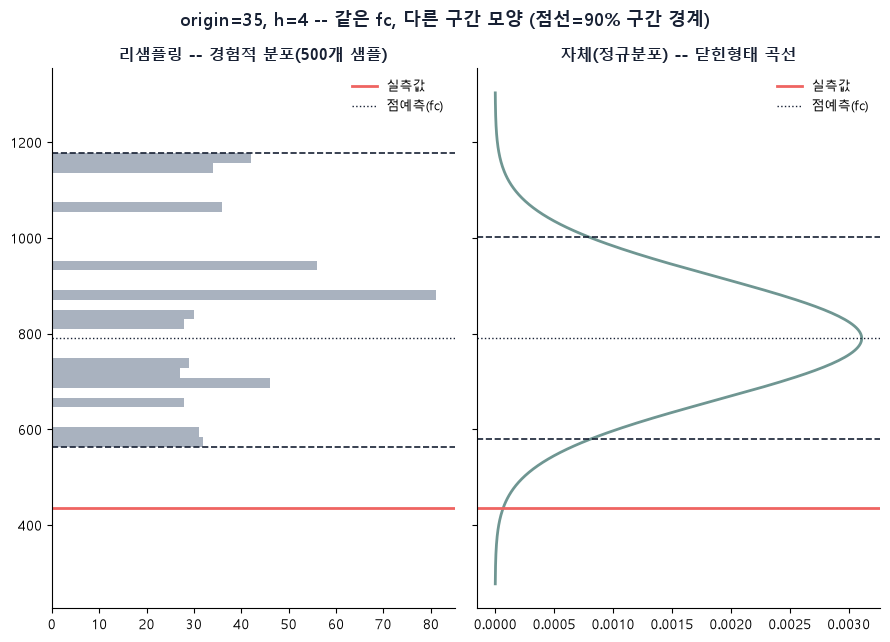

In [4]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(1, 2, figsize=(9, 6.5), sharey=True)
snap = example_snapshot

axes[0].hist(snap["samples"], bins=30, color="#9AA5B4", alpha=0.85, orientation="horizontal")
axes[0].axhline(snap["lo_r"], color="#172033", linestyle="--", linewidth=1.2)
axes[0].axhline(snap["hi_r"], color="#172033", linestyle="--", linewidth=1.2)
axes[0].set_title("리샘플링 -- 경험적 분포(500개 샘플)", fontsize=11.5, fontweight="bold", color="#172033")

y = np.linspace(snap["fc"] - 4 * snap["sigma"], snap["fc"] + 4 * snap["sigma"], 300)
axes[1].plot(stats.norm.pdf(y, snap["fc"], snap["sigma"]), y, color="#6F9692", linewidth=2)
axes[1].axhline(snap["lo_n"], color="#172033", linestyle="--", linewidth=1.2)
axes[1].axhline(snap["hi_n"], color="#172033", linestyle="--", linewidth=1.2)
axes[1].set_title("자체(정규분포) -- 닫힌형태 곡선", fontsize=11.5, fontweight="bold", color="#172033")

for ax in axes:
    ax.axhline(snap["actual"], color="#EF6461", linewidth=2, label="실측값")
    ax.axhline(snap["fc"], color="#172033", linewidth=1, linestyle=":", label="점예측(fc)")
    ax.legend(frameon=False, fontsize=9)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(f"origin={example_origin}, h=4 -- 같은 fc, 다른 구간 모양 (점선=90% 구간 경계)", fontsize=13, fontweight="bold", color="#172033")
fig.tight_layout()
plt.show()


## 2. 결과

커버리지·MSE·CRPS를 계산한다. MSE는 점예측에만 좌우되므로 두 방식이 같은 값이어야 한다(아래에서 확인).

In [5]:
summary = result_df.groupby("방식").agg(
    커버리지=("적중", "mean"), MSE=("mse", "mean"), CRPS=("crps", "mean"),
).round(4)
summary["커버리지"] = (summary["커버리지"] * 100).round(1)
display(summary)
print(f"\nMSE 차이: {abs(summary['MSE'].diff().iloc[-1]):.2e} -- 같은 점예측을 공유하니 사실상 0(동일)이어야 한다.")


,커버리지,MSE,CRPS
방식,,,
리샘플링,76.1,1.1763,0.5769
자체(정규분포),51.1,1.1763,0.6387



MSE 차이: 0.00e+00 -- 같은 점예측을 공유하니 사실상 0(동일)이어야 한다.


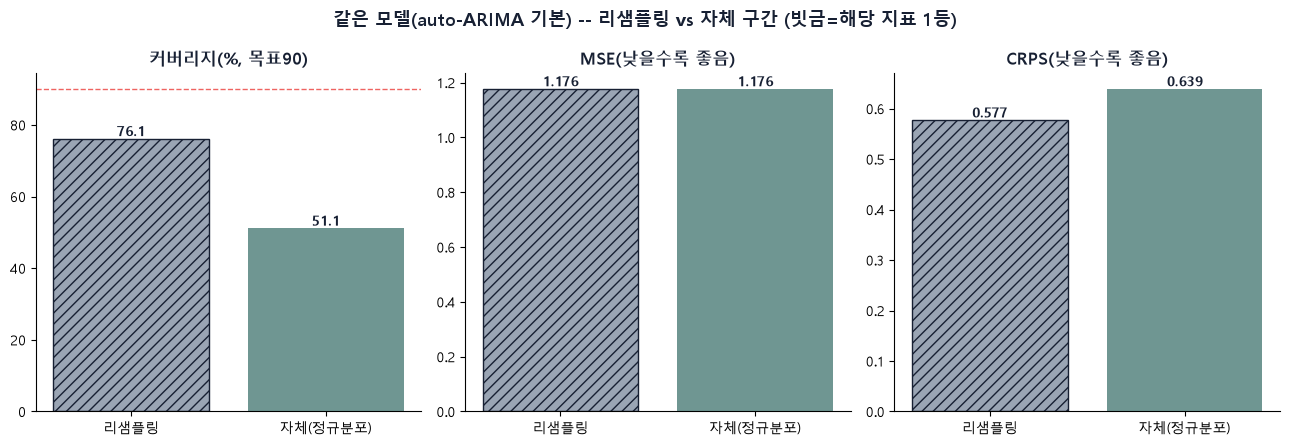

In [6]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
colors = {"리샘플링": "#9AA5B4", "자체(정규분포)": "#6F9692"}
metrics = ["커버리지", "MSE", "CRPS"]
titles = ["커버리지(%, 목표90)", "MSE(낮을수록 좋음)", "CRPS(낮을수록 좋음)"]
better_high = {"커버리지": True, "MSE": False, "CRPS": False}
for ax, metric, title in zip(axes, metrics, titles):
    vals_m = [summary.loc[m, metric] for m in ["리샘플링", "자체(정규분포)"]]
    bars = ax.bar(list(colors.keys()), vals_m, color=list(colors.values()))
    winner_idx = int(np.argmax(vals_m)) if better_high[metric] else int(np.argmin(vals_m))
    bars[winner_idx].set_hatch("///")
    bars[winner_idx].set_edgecolor("#172033")
    for bar, v in zip(bars, vals_m):
        ax.text(bar.get_x() + bar.get_width() / 2, v, f"{v:.1f}" if metric == "커버리지" else f"{v:.3f}",
                ha="center", va="bottom", fontsize=10, fontweight="bold", color="#172033")
    if metric == "커버리지":
        ax.axhline(90, color="#EF6461", linestyle="--", linewidth=1)
    ax.set_title(title, fontsize=12, fontweight="bold", color="#172033")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.suptitle("같은 모델(auto-ARIMA 기본) -- 리샘플링 vs 자체 구간 (빗금=해당 지표 1등)", fontsize=13, fontweight="bold", color="#172033")
fig.tight_layout()
plt.show()


## 3. 결론

같은 모델에서 구간생성법만 바꿨을 때 커버리지·CRPS가 어떻게 달라지는지 확인했다. MSE는 예상대로 동일해서 실질 비교 지표는 커버리지·CRPS다.

**남은 문제**: `auto_arima` 기본값이 이 데이터에 맞는 파라미터인지는 미확인이다(`8-3`). 이 비교는 `8-4`에서 d,p를 확정한 뒤 확정값으로 다시 확인한다(아직 근거 없는 d,p를 미리 쓰면 순환참조가 되기 때문).